# Detección de correos fraudulentos con una red LSTM

**Aplicaciones de Inteligencia Artificial · Segunda evaluación · Primavera 2026**

**Problema.** El área de TI de una empresa recibe correos que imitan a bancos o servicios para robar claves y datos, además de spam. Revisarlos a mano no escala, y una sola persona que caiga puede comprometer una cuenta. Un modelo que estime la probabilidad de fraude permite enviar los correos sospechosos a cuarentena para revisarlos.

**Modelo.** Red LSTM con aprendizaje supervisado: clasificación binaria de texto (seguro o fraudulento), comparada con una regresión logística.

**Flujo:** entorno → datos → exploración → limpieza → separación → vectorización → comparación → arquitectura → entrenamiento → evaluación → prueba → interpretación.

> Antes de ejecutar: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU*.

## Paso 1. Preparar el entorno

Instalamos `kagglehub`, que descarga datasets públicos de Kaggle sin necesidad de cuenta, y revisamos la versión de TensorFlow y si hay GPU.

In [1]:
# Paso 1: preparar el entorno
%pip install -q kagglehub
import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

I0000 00:00:1793760207.003236  189016 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1793760207.986302  189016 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.22.0-rc0
GPU disponible: []


## Paso 2. Importar las bibliotecas

**pandas** maneja la tabla de correos, **re** limpia el texto, **Keras** construye la red y **scikit-learn** separa los datos, crea el modelo de comparación y calcula las métricas.

In [2]:
# Paso 2: importar bibliotecas
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, ConfusionMatrixDisplay)

keras.utils.set_random_seed(42)   # resultados repetibles

## Paso 3. Cargar los datos

Usamos **Phishing Email Detection** de Kaggle: correos con su texto y una etiqueta, `Phishing Email` o `Safe Email`.

In [3]:
# Paso 3: cargar los datos
ruta = kagglehub.dataset_download('subhajournal/phishingemails')
datos = pd.read_csv(f'{ruta}/Phishing_Email.csv')
datos = datos.rename(columns={'Email Text': 'texto', 'Email Type': 'tipo'})[['texto', 'tipo']]
datos.head()

,texto,tipo
0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,the other side of * galicismos * * galicismo *...,Safe Email
2,re : equistar deal tickets are you still avail...,Safe Email
3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,software at incredibly low prices ( 86 % lower...,Phishing Email


## Paso 4. Explorar la estructura de los datos

Revisamos tamaño, balance de clases, datos faltantes, duplicados y largo de los correos. También medimos si alguna palabra delata la clase.

In [4]:
# Paso 4: explorar la estructura de los datos
print("Filas:", len(datos), "| Texto vacío:", datos['texto'].isna().sum())
print("Duplicados exactos:", datos['texto'].duplicated().sum())
print(datos['tipo'].value_counts())

palabras = datos['texto'].dropna().str.split().str.len()
print("Mediana de palabras por correo:", int(palabras.median()),
      "| 90% de los correos tiene menos de:", int(palabras.quantile(0.9)))

con_enron = datos['texto'].fillna('').str.lower().str.contains(r'\benron\b')
print("\n% de correos que dicen 'enron', por tipo:")
print((con_enron.groupby(datos['tipo']).mean() * 100).round(1))

Filas: 18650 | Texto vacío: 16
Duplicados exactos: 1112
tipo
Safe Email        11322
Phishing Email     7328
Name: count, dtype: int64


Mediana de palabras por correo: 160 | 90% de los correos tiene menos de: 729



% de correos que dicen 'enron', por tipo:
tipo
Phishing Email     0.0
Safe Email        20.3
Name: texto, dtype: float64


## Paso 5. Limpiar el texto

Limpieza aplicada a cada correo:
1. Pasar a minúsculas y quitar etiquetas HTML.
2. Reemplazar los enlaces por la palabra `enlaceweb`: importa que haya un enlace, no cuál es.
3. Quitar palabras que delatan el origen de los correos (`enron`, nombres internos y fragmentos de sus direcciones).
4. Dejar solo letras y eliminar duplicados **después** de limpiar.

In [5]:
# Paso 5: limpiar el texto
def limpiar(texto):
    texto = str(texto).lower()
    texto = re.sub(r'<[^>]+>', ' ', texto)                           # etiquetas HTML
    texto = re.sub(r'(https?://|www\.)\S+', ' enlaceweb ', texto)    # enlaces
    texto = re.sub(r'\b(enron|vince|kaminski|hou|ect)\b', ' ', texto)  # atajos del dataset
    texto = re.sub(r'[^a-záéíóúñü ]', ' ', texto)                    # solo letras
    return re.sub(r'\s+', ' ', texto).strip()

datos = datos.dropna(subset=['texto'])
datos['limpio'] = datos['texto'].map(limpiar)
datos = datos[datos['limpio'] != ''].drop_duplicates('limpio')
print("Correos únicos:", len(datos))
print(datos['tipo'].value_counts())
print("\nEjemplo:", datos['limpio'].iloc[0][:150])

Correos únicos: 17103
tipo
Safe Email        10661
Phishing Email     6442
Name: count, dtype: int64

Ejemplo: re disc uniformitarianism re sex lang dick hudson s observations on us use of s on but not d aughter as a vocative are very thought provoking but i am


## Paso 6. Separar los datos

Separamos en **entrenamiento**, **validación** y **prueba** (80% para entrenar y validar, 20% para prueba). La prueba no se usa hasta el final. `stratify` mantiene la misma proporción de clases en cada grupo.

In [6]:
# Paso 6: separar entrenamiento, validación y prueba
X = datos['limpio'].values
y = (datos['tipo'] == 'Phishing Email').astype(int).values   # 1 = fraudulento, 0 = seguro

X_resto, X_prueba, y_resto, y_prueba = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
X_ent, X_val, y_ent, y_val = train_test_split(
    X_resto, y_resto, test_size=0.15, stratify=y_resto, random_state=42)
print("Entrenamiento:", len(X_ent), "| Validación:", len(X_val), "| Prueba:", len(X_prueba))

Entrenamiento: 11629 | Validación: 2053 | Prueba: 3421


## Paso 7. Convertir las palabras en números

`TextVectorization` crea un vocabulario de 20.000 palabras y transforma cada correo en 200 números. Los correos más cortos se rellenan con ceros y los largos se cortan.

In [7]:
# Paso 7: convertir las palabras en números
VOCABULARIO, LARGO = 20000, 200
vectorizador = layers.TextVectorization(
    max_tokens=VOCABULARIO, output_sequence_length=LARGO, standardize=None)
vectorizador.adapt(X_ent)   # aprende el vocabulario solo con entrenamiento

X_ent_num = vectorizador(X_ent)
X_val_num = vectorizador(X_val)
X_prueba_num = vectorizador(X_prueba)
print("Forma:", X_ent_num.shape)
print("Correo:", X_ent[0][:60])
print("Números:", X_ent_num[0][:10].numpy())

Forma: (11629, 200)
Correo: syntax of east asian languages workshop usc workshop on synt
Números: [ 281    3 1056 1661  104  149 3129  149   12  281]


## Paso 8. Crear una línea de comparación

Antes de la red entrenamos una **regresión logística**, un modelo simple visto en el curso. Solo mira qué palabras aparecen, no su orden. Sirve para saber si la LSTM realmente aporta.

In [8]:
# Paso 8: línea de comparación (regresión logística)
tfidf = TfidfVectorizer(max_features=VOCABULARIO)
base = LogisticRegression(max_iter=1000).fit(tfidf.fit_transform(X_ent), y_ent)
prob_base = base.predict_proba(tfidf.transform(X_prueba))[:, 1]
print(classification_report(y_prueba, (prob_base >= 0.5).astype(int),
                            target_names=['Seguro', 'Fraudulento'], digits=3))

              precision    recall  f1-score   support

      Seguro      0.965     0.984     0.974      2132
 Fraudulento      0.972     0.940     0.956      1289

    accuracy                          0.967      3421
   macro avg      0.968     0.962     0.965      3421
weighted avg      0.967     0.967     0.967      3421



## Paso 9. Construir la arquitectura LSTM

| Capa | Qué hace |
|---|---|
| `Embedding(20000, 64)` | Convierte cada número de palabra en un vector de 64 valores. Palabras de uso parecido terminan con vectores parecidos. |
| `LSTM(64)` | Lee el correo palabra por palabra y mantiene una memoria de lo leído. |
| `Dropout(0.5)` | Al entrenar, pone en cero al azar la mitad de los valores que entrega la LSTM, para reducir el sobreajuste. |
| `Dense(1, sigmoid)` | Entrega la probabilidad de que el correo sea fraudulento. |

In [9]:
# Paso 9: construir la arquitectura
modelo = keras.Sequential([
    keras.Input(shape=(LARGO,)),
    layers.Embedding(VOCABULARIO, 64, mask_zero=True),  # ignora el relleno de ceros
    layers.LSTM(64),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,089 (5.01 MB)

 Trainable params: 1,313,089 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

## Paso 10. Configurar el entrenamiento

- **Adam**: ajusta los pesos usando el gradiente.
- **Binary cross-entropy**: `L = -[y·log(p) + (1-y)·log(1-p)]`, castiga fuerte cuando se equivoca con mucha seguridad.
- **Recall**: de los correos fraudulentos, cuántos detecta. **Precisión**: de los que marca, cuántos son fraude.

In [10]:
# Paso 10: configurar el entrenamiento
modelo.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy',
             keras.metrics.Recall(name='recall'),
             keras.metrics.Precision(name='precision')]
)

## Paso 11. Entrenar el modelo

- **Época**: una pasada por todos los correos de entrenamiento.
- **Batch de 32**: se actualizan los pesos cada 32 correos.
- **EarlyStopping**: si la pérdida de validación no mejora en 2 épocas, se detiene y recupera los mejores pesos.

In [11]:
# Paso 11: entrenar el modelo
parada = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=2, restore_best_weights=True)
historial = modelo.fit(
    X_ent_num, y_ent,
    validation_data=(X_val_num, y_val),
    epochs=6,
    batch_size=32,
    callbacks=[parada],
    verbose=2
)

Epoch 1/6


364/364 - 18s - 50ms/step - accuracy: 0.9059 - loss: 0.2485 - precision: 0.8923 - recall: 0.8532 - val_accuracy: 0.8246 - val_loss: 0.5317 - val_precision: 0.9859 - val_recall: 0.5420


Epoch 2/6


364/364 - 17s - 46ms/step - accuracy: 0.9556 - loss: 0.1480 - precision: 0.9570 - recall: 0.9237 - val_accuracy: 0.9688 - val_loss: 0.1113 - val_precision: 0.9671 - val_recall: 0.9495


Epoch 3/6


364/364 - 17s - 46ms/step - accuracy: 0.9480 - loss: 0.1979 - precision: 0.9502 - recall: 0.9096 - val_accuracy: 0.9479 - val_loss: 0.1679 - val_precision: 0.9524 - val_recall: 0.9069


Epoch 4/6


364/364 - 17s - 46ms/step - accuracy: 0.9809 - loss: 0.0696 - precision: 0.9742 - recall: 0.9751 - val_accuracy: 0.9649 - val_loss: 0.1215 - val_precision: 0.9655 - val_recall: 0.9405


## Paso 12. Curvas de aprendizaje

Si la validación empeora mientras el entrenamiento mejora, hay sobreajuste.

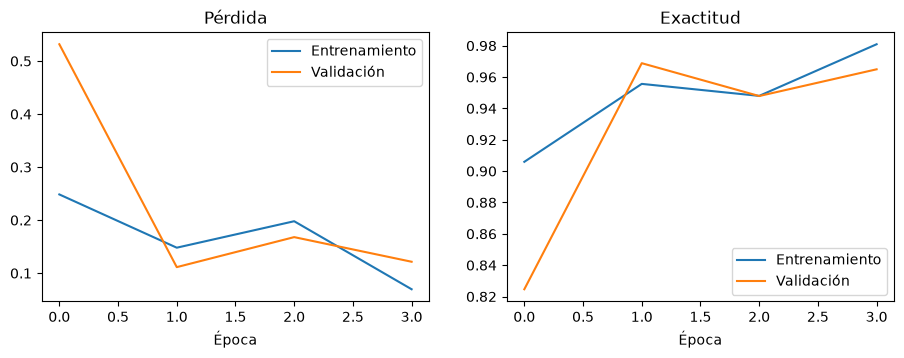

In [12]:
# Paso 12: curvas de aprendizaje
h = historial.history
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(h['loss'], label='Entrenamiento'); a1.plot(h['val_loss'], label='Validación')
a1.set_title('Pérdida'); a1.set_xlabel('Época'); a1.legend()
a2.plot(h['accuracy'], label='Entrenamiento'); a2.plot(h['val_accuracy'], label='Validación')
a2.set_title('Exactitud'); a2.set_xlabel('Época'); a2.legend()
plt.show()

## Paso 13. Evaluar y comparar

Evaluamos con los correos de prueba y comparamos con la regresión logística.

              precision    recall  f1-score   support

      Seguro      0.967     0.981     0.974      2132
 Fraudulento      0.967     0.945     0.956      1289

    accuracy                          0.967      3421
   macro avg      0.967     0.963     0.965      3421
weighted avg      0.967     0.967     0.967      3421

AUC LSTM: 0.991 | AUC regresión logística: 0.995
Exactitud LSTM: 0.967 | regresión logística: 0.967


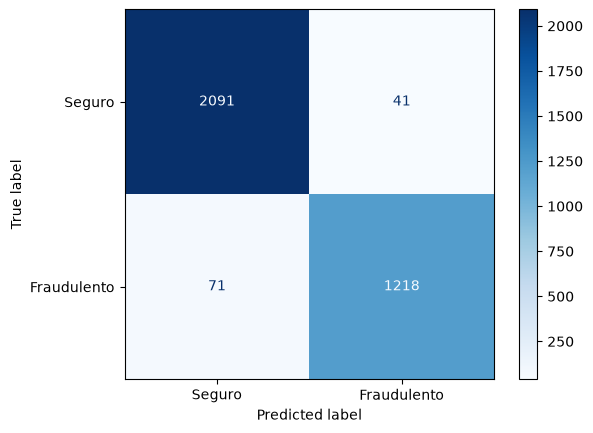

In [13]:
# Paso 13: evaluar y comparar
prob_lstm = modelo.predict(X_prueba_num, verbose=0).ravel()
pred_lstm = (prob_lstm >= 0.5).astype(int)
print(classification_report(y_prueba, pred_lstm,
                            target_names=['Seguro', 'Fraudulento'], digits=3))
print("AUC LSTM:", round(roc_auc_score(y_prueba, prob_lstm), 3),
      "| AUC regresión logística:", round(roc_auc_score(y_prueba, prob_base), 3))
print("Exactitud LSTM:", round((pred_lstm == y_prueba).mean(), 3),
      "| regresión logística:", round(((prob_base >= 0.5).astype(int) == y_prueba).mean(), 3))
ConfusionMatrixDisplay(confusion_matrix(y_prueba, pred_lstm),
                       display_labels=['Seguro', 'Fraudulento']).plot(cmap='Blues')
plt.show()

## Paso 14. Probar con correos nuevos

La función `clasificar_correo` recibe un texto, lo limpia igual que en el entrenamiento y entrega la probabilidad de fraude. Los cuatro correos fueron escritos para esta prueba, no vienen del dataset. Los enlaces usan el dominio reservado `.invalid`, que no existe.

In [14]:
# Paso 14: probar con correos nuevos
def clasificar_correo(texto, umbral=0.5):
    numeros = vectorizador([limpiar(texto)])
    prob = float(modelo.predict(numeros, verbose=0)[0, 0])
    return prob, ('FRAUDULENTO' if prob >= umbral else 'SEGURO')

correos = [
    ("Fraude", "Banco", """Subject: URGENT: Your Bank Account Will Be Suspended
Dear Customer, We have detected unusual activity on your bank account. For security reasons, we have temporarily restricted certain transactions.
To prevent your account from being permanently suspended, you must verify your personal information within the next 24 hours.
Please confirm your identity using the following link: https://secure-bank-validation.invalid/confirm
Failure to complete this verification may result in the suspension of your online banking access.
Sincerely, Bank Security Department"""),
    ("Fraude", "Paquete", """Subject: Delivery Failed: Action Required for Your Package
Hello, Your package has arrived at our distribution center, but we were unable to complete the delivery due to an issue with the registered address.
To schedule another delivery attempt, please confirm your shipping information and pay a small processing fee of $2.99.
You can update your delivery details here: https://parcel-delivery-update.invalid/reschedule
Your package will be held for 48 hours before being returned to the sender.
Thank you for your understanding. Express Delivery Support Team"""),
    ("Fraude", "Soporte TI", """From: Academic IT Support <support@campus-account-services.invalid>
Subject: Important Update Regarding Your Student Account
Dear Student, We are currently updating the authentication systems used by our academic platform.
As part of this process, some students are required to confirm their account information to maintain access to their courses and learning materials.
You can review your account status through the following portal: https://campus-account-services.invalid/verification
This procedure ensures that your student account remains correctly connected to our institutional services.
Best regards, Academic IT Support Team"""),
    ("Seguro", "Coordinación", """From: Academic Coordination <coordination@university-example.invalid>
Subject: Information About Upcoming Project Presentations
Dear Students, We would like to inform you that project presentations for this semester will begin next week.
Each group should prepare a presentation lasting approximately 10 minutes, covering the project objectives, technologies used, and main results achieved.
Please review the evaluation rubric available in your course materials to ensure that all required topics are included.
If you have any questions, feel free to ask during the next class.
Best regards, Academic Coordination Office"""),
]
for real, nombre, correo in correos:
    prob, decision = clasificar_correo(correo)
    print(f"{nombre:13s} | Real: {real:7s} | Modelo: {decision:12s} | P(fraude)={prob:6.1%}")

Banco         | Real: Fraude  | Modelo: FRAUDULENTO  | P(fraude)= 99.1%


Paquete       | Real: Fraude  | Modelo: FRAUDULENTO  | P(fraude)= 97.8%
Soporte TI    | Real: Fraude  | Modelo: SEGURO       | P(fraude)=  4.1%
Coordinación  | Real: Seguro  | Modelo: SEGURO       | P(fraude)=  0.4%


## Paso 15. Interpretar el resultado

Traducimos las métricas al lenguaje del problema.

In [15]:
# Paso 15: interpretar en términos del problema
vn, fp, fn, vp = confusion_matrix(y_prueba, pred_lstm).ravel()
print(f"De {vp+fn} correos fraudulentos, detectó {vp} ({vp/(vp+fn):.1%}) y dejó pasar {fn}.")
print(f"De {vn+fp} correos seguros, {fp} ({fp/(vn+fp):.1%}) quedarían marcados por error.")

De 1289 correos fraudulentos, detectó 1218 (94.5%) y dejó pasar 71.
De 2132 correos seguros, 41 (1.9%) quedarían marcados por error.


## Paso 16 (opcional). Efecto del umbral

Bajar el umbral detecta más fraude, pero aumenta las falsas alarmas. Es una decisión del negocio.

In [16]:
# Paso 16: efecto del umbral
for umbral in [0.3, 0.5, 0.7, 0.9]:
    pred = (prob_lstm >= umbral).astype(int)
    vn_u, fp_u, fn_u, vp_u = confusion_matrix(y_prueba, pred).ravel()
    print(f"umbral {umbral}: detecta {vp_u/(vp_u+fn_u):.1%} del fraude | "
          f"falsas alarmas {fp_u/(vn_u+fp_u):.1%}")

umbral 0.3: detecta 95.7% del fraude | falsas alarmas 2.4%
umbral 0.5: detecta 94.5% del fraude | falsas alarmas 1.9%
umbral 0.7: detecta 92.1% del fraude | falsas alarmas 1.5%
umbral 0.9: detecta 85.9% del fraude | falsas alarmas 0.8%


## Paso 17. Guardar el modelo (para la defensa)

Guardamos el vectorizador y la red juntos, para clasificar texto en la defensa sin volver a entrenar.

In [17]:
# Paso 17: guardar el modelo completo
modelo_completo = keras.Sequential([
    keras.Input(shape=(1,), dtype='string'),
    vectorizador,
    modelo
])
modelo_completo.save('modelo_phishing.keras')
print("Modelo guardado.")
try:
    from google.colab import files
    files.download('modelo_phishing.keras')
except ImportError:
    pass

Modelo guardado.


## Modo defensa: cargar el modelo sin reentrenar

Ejecutar los pasos 1, 2, 3, 5 y 6, subir `modelo_phishing.keras` al panel de archivos de Colab y ejecutar esta celda.

In [18]:
# Modo defensa: cargar el modelo guardado
import tensorflow as tf
cargado = keras.models.load_model('modelo_phishing.keras')

def clasificar_cargado(texto, umbral=0.5):
    prob = float(cargado.predict(tf.constant([[limpiar(texto)]]), verbose=0)[0, 0])
    return prob, ('FRAUDULENTO' if prob >= umbral else 'SEGURO')

prob_def = cargado.predict(tf.constant(X_prueba.reshape(-1, 1)), verbose=0).ravel()
print("Exactitud en prueba:", round(((prob_def >= 0.5).astype(int) == y_prueba).mean(), 3))
print(clasificar_cargado("Your account has been suspended. Click here and confirm your password now."))

Exactitud en prueba: 0.967
(0.9872723817825317, 'FRAUDULENTO')


## Conclusión y mejoras

**¿Resuelve el problema?** **Parcialmente.** El modelo funciona como filtro de apoyo contra el fraude evidente, pero en la prueba dejó pasar un fraude bien escrito, así que no reemplaza otros controles.

**Limitaciones**
- La regresión logística rinde prácticamente igual: en este dataset, la LSTM no mostró una mejora medible.
- Los datos están en inglés y mezclan phishing con spam común, y cerca del 20% de los correos seguros menciona a una sola empresa (Enron).
- Deja pasar fraudes bien escritos y sin lenguaje de urgencia, como el correo de soporte TI de la prueba.
- Puede marcar como fraude correos legítimos automáticos, como una recuperación de contraseña.
- Los fraudes actuales pueden ser distintos a los de este dataset.

**Mejoras posibles**
- Entrenar con correos recientes y en español.
- Sumar señales como el remitente y el dominio real de los enlaces.
- Separar phishing de spam en clases distintas.
- Enviar lo sospechoso a cuarentena, con revisión humana, y cuidar la privacidad del contenido de los correos (Ley 21.719).